# Les députés représentent-ils bien leurs circonscriptions ?

*Introduction : à rédiger...*

**Problématique.** Nous comparons le profil de chaque député (âge, genre, profession, groupe politique) à celui de sa circonscription (indicateurs INSEE, résultats électoraux), pour mesurer dans quelle mesure l'Assemblée ressemble aux territoires qu'elle représente.

# 1. Données
## 1.1 Sources

| Source | Contenu | Accès |
|---|---|---|
| INSEE, indicateurs par circonscription législative (2022) | 124 indicateurs socio-économiques | Fichier Excel téléchargé |
| INSEE, composition des circonscriptions | Correspondance communes - circonscriptions | Fichier Excel téléchargé |
| Députés actifs de l'Assemblée nationale | Âge, genre, groupe, scores parlementaires | API data.gouv.fr |

Les fichiers bruts sont « gelés » dans `data/data_brut` pour que le projet reste rejouable si les sites changent.

In [1]:
from extraction_donnees import charger_donnees
from jointures import joindre_deputes_insee
from descriptif import (
    preparer_deputes, tableau_groupes, valeurs_manquantes,
    graphique_deputes, graphique_insee,
)

deputes, insee_indic, insee_compo, dico_insee = charger_donnees()
deputes = preparer_deputes(deputes)

print("Députés :", deputes.shape)
print("Indicateurs INSEE :", insee_indic.shape)
print("Composition communes-circonscriptions :", insee_compo.shape)

Députés : (574, 29)
Indicateurs INSEE : (567, 125)
Composition communes-circonscriptions : (35150, 8)


## 1.2 Nettoyage

Les données brutes n'étaient pas exploitables telles quelles :

- **Fichier INSEE des indicateurs** : les données sont dans le premier onglet, précédées de 7 lignes de métadonnées. La fonction `lire_excel_insee` prend donc l'onglet et la ligne d'en-tête en paramètres.
- **Clé de jointure `code_circo`** : l'INSEE utilise 5 caractères (`75018`), la base des députés les départements sur 3 chiffres et les circonscriptions sur 2. Nous avons harmonisé les deux au format INSEE.
- **Corse** : `2a001` côté députés, `2A001` côté INSEE, d'où un passage en majuscules.
- **Saint-Barthélemy** : l'INSEE la regroupe avec Saint-Martin (`97801`), le code `97701` a été rattaché à celle-ci.
- **Valeurs `s` et `nd`** de l'INSEE (secret statistique, non déterminé) : converties en valeurs manquantes.

In [2]:
df = joindre_deputes_insee(deputes, insee_indic)

print("Forme de la table jointe :", df.shape)
print(df["indicateur_present"].value_counts())
print(sorted(df.loc[~df["indicateur_present"], "code_circo"]))

Forme de la table jointe : (574, 154)
indicateur_present
True     563
False     11
Name: count, dtype: int64
['99001', '99002', '99003', '99004', '99005', '99006', '99007', '99008', '99009', '99010', '99011']


## 1.3 Jointure

La jointure est faite à gauche sur `code_circo` : sur 574 députés, **563 ont les indicateurs INSEE de leur circonscription**. Les 11 restants sont les circonscriptions des Français de l'étranger (`99001` à `99011`), pour lesquelles l'INSEE ne publie pas d'indicateurs. Nous les conservons avec des valeurs manquantes, car ils restent utiles pour les statistiques sur les députés eux-mêmes.

Côté INSEE, trois circonscriptions n'ont pas de député dans la base : l'Aube (2e), la Charente-Maritime (5e) et la Gironde (11e). Leurs titulaires ont été élus sénateurs fin septembre 2026 et ont été remplacés par leurs suppléants, qui ne figurent pas encore dans le fichier des députés téléchargé le 14 novembre 2026. La ligne `00000` de l'INSEE est une moyenne nationale, pas une circonscription : elle est exclue.

## 1.4 Description des données

### Les députés

,effectif,age_moyen,part_femmes
groupeAbrev,,,
RN,121,50.2,32.2
EPR,90,53.1,50.0
LFI-NFP,70,44.3,42.9
SOC,68,56.2,41.2
DR,46,54.5,30.4
ECOS,38,49.8,47.4
DEM,37,57.7,40.5
HOR,35,55.8,34.3
LIOT,24,59.4,25.0


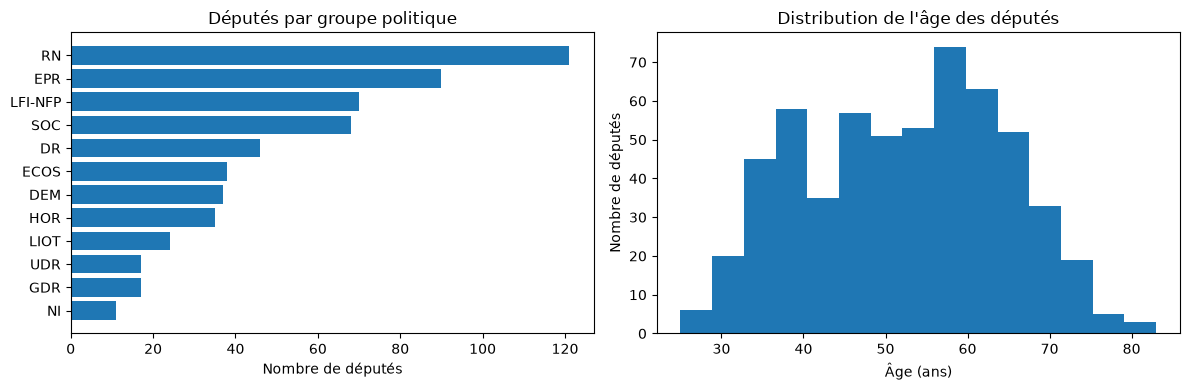

In [3]:
display(tableau_groupes(deputes))
graphique_deputes(deputes);

L'Assemblée compte 574 députés actifs répartis en 12 groupes, dont 38 % de femmes (220). Le RN (121 députés) et EPR (90) sont les groupes les plus nombreux. Trois groupes (GDR, UDR, NI) comptent moins de 20 députés : toute moyenne calculée sur eux sera peu fiable.

L'âge moyen des députés est d'environ 52 ans, mais il varie fortement selon les groupes : de 44 ans pour LFI-NFP et l'UDR à 59 ans pour LIOT. La parité varie aussi beaucoup, de 50 % de femmes chez EPR à 18 % à l'UDR. Ces écarts entre groupes justifient de ne pas traiter les députés comme un ensemble homogène dans la suite.

In [4]:
display(valeurs_manquantes(deputes))

,nb,pct
website,363,63.2
facebook,257,44.8
twitter,218,38.0
scoreParticipationSpecialite,4,0.7
scoreLoyaute,1,0.2
scoreMajorite,1,0.2


Les valeurs manquantes de la base des députés concernent surtout les réseaux sociaux et le site web (38 % à 63 %), variables que nous n'utiliserons pas. Les scores parlementaires sont quasi complets (1 à 4 valeurs manquantes sur 574).

### Les indicateurs INSEE

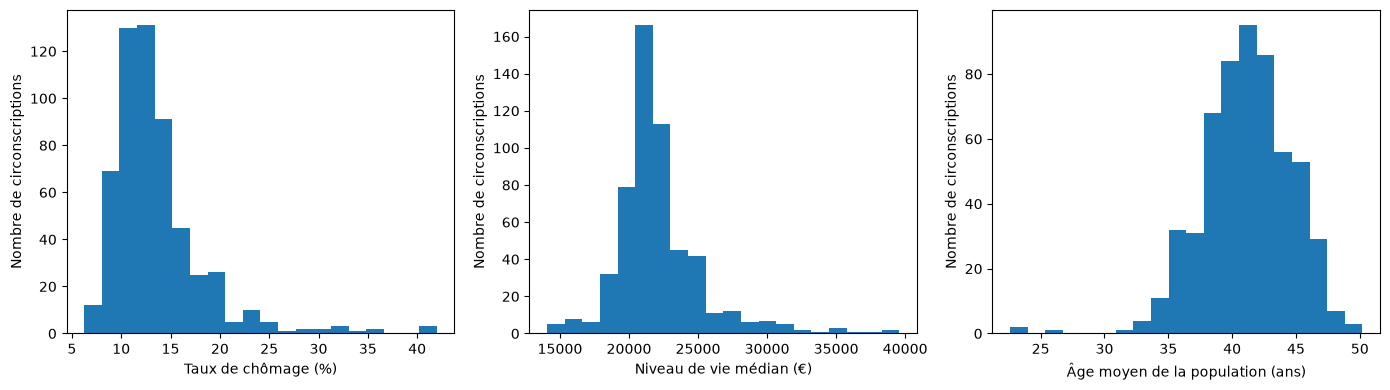

In [5]:
graphique_insee(df);

Les circonscriptions diffèrent nettement. Le taux de chômage (calculé comme chômeurs / population active, au sens du recensement, donc plus élevé que le taux officiel) a une médiane de 12,6 % et va de 6,2 % à 42 %. Les valeurs les plus élevées sont toutes en outre-mer (Mayotte, Guyane, La Réunion : de 36 % à 42 %), ce qui en fait des cas atypiques. Le niveau de vie médian va de 14 070 € à 39 590 € (médiane 21 590 €). L'âge moyen de la population, autour de 41 ans, est bien inférieur à celui des députés, mais les deux ne sont pas strictement comparables (l'âge INSEE inclut les enfants). Le niveau de vie médian est manquant pour 16 circonscriptions, toutes situées en outre-mer, que la source (Filosofi) ne semble pas couvrir.

         age  dec50  ecart_age
count  563.0  563.0      563.0
mean    52.2   41.4       10.8
std     12.2    5.1       12.4
min     25.0   17.0      -19.0
25%     42.0   38.0        2.0
50%     53.0   42.0       12.0
75%     61.0   45.0       19.0
max     83.0   55.0       41.0
toutes circonscriptions    0.17
métropole seule            0.18
dtype: float64
(np.float64(0.17849904160116345), np.float64(3.234018329464958e-05))


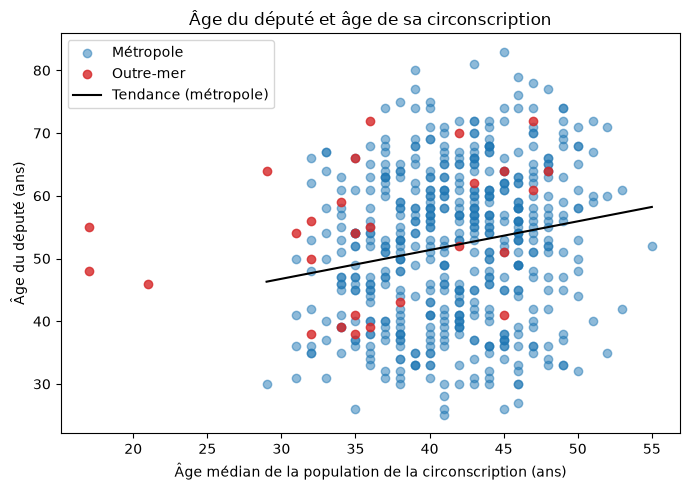

In [6]:
from representativite import preparer_comparaison, correlations_age, graphique_age

comp = preparer_comparaison(df)
print(comp[["age", "dec50", "ecart_age"]].describe().round(1))
print(correlations_age(comp).round(2))
graphique_age(comp);

from representativite import test_correlation_age
print(test_correlation_age(comp))

### Âge du député et âge de sa circonscription

Pour chaque circonscription métropolitaine et d'outre-mer disposant d'indicateurs INSEE (563 sur 574), nous rapprochons l'âge du député de l'âge médian de la population de sa circonscription. Les deux ne sont pas directement comparables : la population INSEE inclut les enfants, ce qui explique que l'écart moyen soit positif (environ 11 ans). Seule la variation de cet écart entre circonscriptions est donc interprétable.

Le nuage de points montre un lien positif mais faible : la corrélation est de 0,17 sur l'ensemble des circonscriptions et de 0,18 en métropole, où elle est statistiquement significative (test de Pearson, p-value < 0,001). L'âge médian de la circonscription n'explique ainsi qu'environ 3 % de la variation de l'âge des députés. Dans une circonscription d'âge médian donné, on trouve des députés de 25 à 83 ans. Les circonscriptions d'outre-mer, nettement plus jeunes (âge médian de 17 à 21 ans pour trois d'entre elles), ne modifient pas ce constat.

Nos données suggèrent donc que l'âge des députés dépend peu de celui de leurs électeurs. Cette corrélation décrit des circonscriptions, et ne dit rien du comportement des électeurs ni des partis dans le choix des candidats.

In [7]:
from representativite import comparer_genre

tab_genre = comparer_genre(comp)
print("Effectifs (femmes, hommes) :", tab_genre.attrs["effectifs"])
display(tab_genre.round(3))

Effectifs (femmes, hommes) : (209, 327)


,moyenne_femmes,moyenne_hommes,ecart,p_value
indicateur,,,,
Part de la population dans un pôle urbain (%),54.352,47.537,6.815,0.013
Part de la population en commune rurale non périurbaine (%),12.682,16.631,-3.949,0.019
Niveau de vie médian (€),22819.426,21913.333,906.093,0.003
Taux de pauvreté (%),14.279,14.787,-0.508,0.301
Part de cadres parmi les actifs (%),18.069,14.874,3.195,0.000
Part d'ouvriers parmi les actifs (%),20.058,22.763,-2.705,0.000
Part d'actifs diplômés bac+5 ou plus (%),15.715,12.422,3.293,0.000
Taux de chômage (%),12.693,13.118,-0.424,0.194
Âge médian de la population (ans),41.177,42.058,-0.881,0.028


### Genre du député et profil de la circonscription

Nous comparons, en métropole (536 circonscriptions : 209 élues femmes, 327 élus hommes), les caractéristiques des circonscriptions selon le genre du député. L'outre-mer et les Français de l'étranger sont exclus, car leurs profils sont très atypiques et plusieurs indicateurs y sont absents. Les groupes sont comparés par un test de Mann-Whitney, qui ne suppose pas de distribution normale.

Les circonscriptions des députées sont plus urbaines et plus favorisées : elles comptent en moyenne 3,2 points de cadres de plus (18,1 % contre 14,9 %), 3,3 points de diplômés bac+5 de plus, 2,7 points d'ouvriers de moins, et un niveau de vie médian supérieur d'environ 900 € (22 800 € contre 21 900 €). Ces quatre écarts restent significatifs après correction pour les tests multiples (seuil de Bonferroni d'environ 0,006). La part de population en pôle urbain (+6,8 points), la part de ruralité (−3,9 points) et l'âge médian (−0,9 an) vont dans le même sens mais ne résistent pas à cette correction : nous les considérons comme des tendances. Le taux de pauvreté et le taux de chômage ne diffèrent pas significativement.

Ces écarts sont modestes en valeur absolue et décrivent des moyennes : les deux groupes de circonscriptions se recouvrent largement. Ils ne montrent pas que le genre « cause » le profil de la circonscription. Une explication possible, que nous n'avons pas testée, tient à la géographie des partis : les groupes qui présentent davantage de femmes pourraient être mieux implantés dans les territoires urbains et aisés.

In [8]:
from representativite import comparer_genre_intra_groupe

tab_intra = comparer_genre_intra_groupe(comp)
print("Groupes gardés :", tab_intra.attrs["groupes"])
print("Circonscriptions :", tab_intra.attrs["effectif"])
display(tab_intra.round(3))

Groupes gardés : ['DEM', 'DR', 'ECOS', 'EPR', 'HOR', 'LFI-NFP', 'RN', 'SOC']
Circonscriptions : 480


,ecart_intra_groupe,p_value
indicateur,,
Part de cadres parmi les actifs (%),1.895,0.046
Part d'actifs diplômés bac+5 ou plus (%),1.990,0.065
Part d'ouvriers parmi les actifs (%),-1.882,0.001
Niveau de vie médian (€),685.165,0.051
Part de la population dans un pôle urbain (%),3.958,0.075


#### Une différence due à la géographie des partis ?

Les femmes ne sont pas réparties au hasard entre les groupes politiques, et les groupes sont inégalement implantés selon les territoires. Pour savoir si l'écart précédent reflète seulement cela, nous retirons de chaque indicateur la moyenne du groupe du député, puis nous comparons les femmes et les hommes sur cet écart « interne au groupe ». Nous gardons les huit groupes comptant au moins 20 députés en métropole (480 circonscriptions), car la moyenne d'un petit groupe est trop fragile, et nous testons les cinq indicateurs les plus marqués pour limiter les tests multiples.

Les écarts se réduisent, de 25 % à 40 % selon l'indicateur, mais gardent le même signe : à groupe politique égal, les députées sont encore élues dans des circonscriptions comptant environ 1,9 point de cadres de plus, 1,9 point d'ouvriers de moins, 2,0 points de diplômés bac+5 de plus et un niveau de vie médian supérieur d'environ 685 €. Seul l'écart sur la part d'ouvriers résiste à la correction de Bonferroni (seuil de 0,01) ; les autres sont des tendances (p-values de 0,046 à 0,075).

La géographie des partis explique donc une partie de la différence, mais probablement pas toute. Cette conclusion reste prudente : l'échantillon est réduit par rapport à l'analyse précédente, et nous ne contrôlons ni l'ancienneté du député ni le type de scrutin.

In [9]:
from professions import ajouter_categorie_job

deputes = ajouter_categorie_job(deputes)
display(deputes["csp_depute"].value_counts().to_frame("effectif"))

,effectif
csp_depute,
cad,347
art,55
int,40
non_classe,33
inactif,29
emp,27
politique,22
agr,16
ouv,5


Députés classés : 490


,deputes,population_active,ecart
Agriculteurs exploitants,3.3,1.4,1.8
"Artisans, commerçants, chefs d'entreprise",11.2,6.3,4.9
Cadres et prof. intellectuelles supérieures,70.8,16.0,54.8
Professions intermédiaires,8.2,24.6,-16.4
Employés,5.5,28.4,-22.8
Ouvriers,1.0,21.4,-20.4


,effectif,part_deputes_cadres,part_cadres_circo
quartile_cadres,,,
Q1 (moins de cadres),120,65.8,8.3
Q2,111,71.2,11.0
Q3,112,70.5,15.3
Q4 (plus de cadres),114,75.4,29.5


p-value (chi2) : 0.45402189372534496


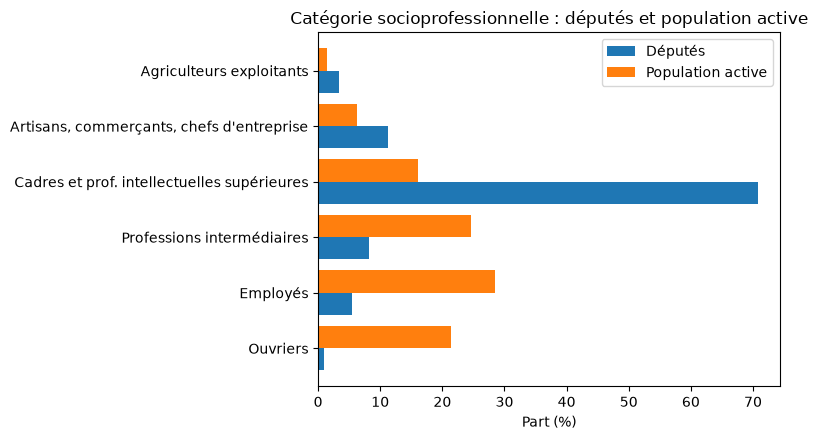

In [10]:
from professions import ajouter_categorie_job
from representativite import comparer_csp, graphique_csp, part_cadres_par_quartile

tab_csp = comparer_csp(ajouter_categorie_job(deputes), insee_indic)
print("Députés classés :", tab_csp.attrs["effectif"])
display(tab_csp)
graphique_csp(tab_csp);

comp_csp = ajouter_categorie_job(comp)
quartiles = part_cadres_par_quartile(comp_csp)
display(quartiles)
print("p-value (chi2) :", quartiles.attrs["p_value"])

### Catégorie socioprofessionnelle des députés

Nous recodons la profession déclarée de chaque député en six grandes catégories comparables à celles de l'INSEE (règles dans `professions.py`) : la nomenclature PCS lorsque la profession est codée (20 % des députés), des règles par mots-clés sinon. Sur 574 députés, 490 sont classés ; 84 sont exclus de la comparaison (22 collaborateurs ou membres de cabinets, 29 personnes sans activité ou retraitées sans ancien métier connu, 33 libellés trop ambigus).

Les cadres et professions intellectuelles supérieures représentent 70,8 % des députés classés, contre 16,0 % de la population active. À l'inverse, les employés (5,5 % contre 28,4 %) et les ouvriers (1,0 % contre 21,4 %) sont très peu présents : à eux deux, ils forment près de la moitié des actifs mais 6,5 % des députés. Les professions intermédiaires sont également sous-représentées (8,2 % contre 24,6 %). Les artisans, commerçants et chefs d'entreprise (11,2 % contre 6,3 %) et les agriculteurs exploitants (3,3 % contre 1,4 %) sont un peu surreprésentés, mais les effectifs sont faibles (16 agriculteurs et 5 ouvriers parmi les députés classés), ce qui rend ces parts fragiles.

Cette surreprésentation ne dépend pas de la circonscription : la part de députés cadres est de 66 % dans le quart des circonscriptions comptant le moins de cadres et de 75 % dans celui qui en compte le plus, mais cette différence n'est pas significative (test du chi2, p = 0,45). Même dans les territoires où les cadres sont rares, les élus sont très majoritairement cadres.

Ces résultats reposent sur la profession déclarée par les députés, qui peut valoriser leur parcours, et sur un recodage en partie subjectif (règles détaillées dans le code, 5,7 % de libellés non classés).

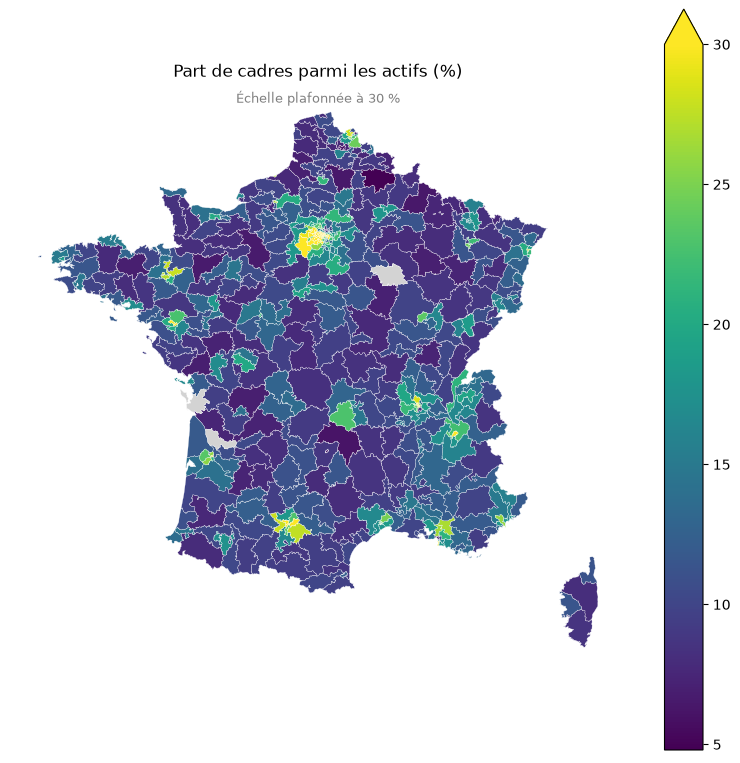

In [11]:
from cartes import preparer_carte, carte_indicateur

carte = preparer_carte()
carte_indicateur(carte, "act_cad", "Part de cadres parmi les actifs (%)", vmax=30);

La carte de la part de cadres parmi les actifs montre une forte concentration spatiale. L'échelle de couleurs est plafonnée à 30 % pour que Paris et sa proche couronne, où la part de cadres est la plus élevée, n'écrasent pas le reste de la carte. Dans la grande majorité des circonscriptions, la part de cadres est comprise entre 5 % et 15 %. Les valeurs élevées se concentrent dans les grandes agglomérations (Paris, Lyon, Toulouse, Lille, Nantes, Rennes, Bordeaux, Grenoble). Les territoires ruraux sont presque tous en dessous de 10 %. Les circonscriptions en gris (Aube 2e, Charente-Maritime 5e, Gironde 11e) n'ont pas de député dans notre base (section 1.3). Sept circonscriptions d'outre-mer (Saint-Martin, Polynésie, Wallis-et-Futuna, Nouvelle-Calédonie) n'ont pas de contour dans le fichier utilisé, et les autres circonscriptions d'outre-mer sont exclues de la carte pour lisibilité. La carte décrit les circonscriptions, pas leurs élus : la suite du rapport compare les deux.

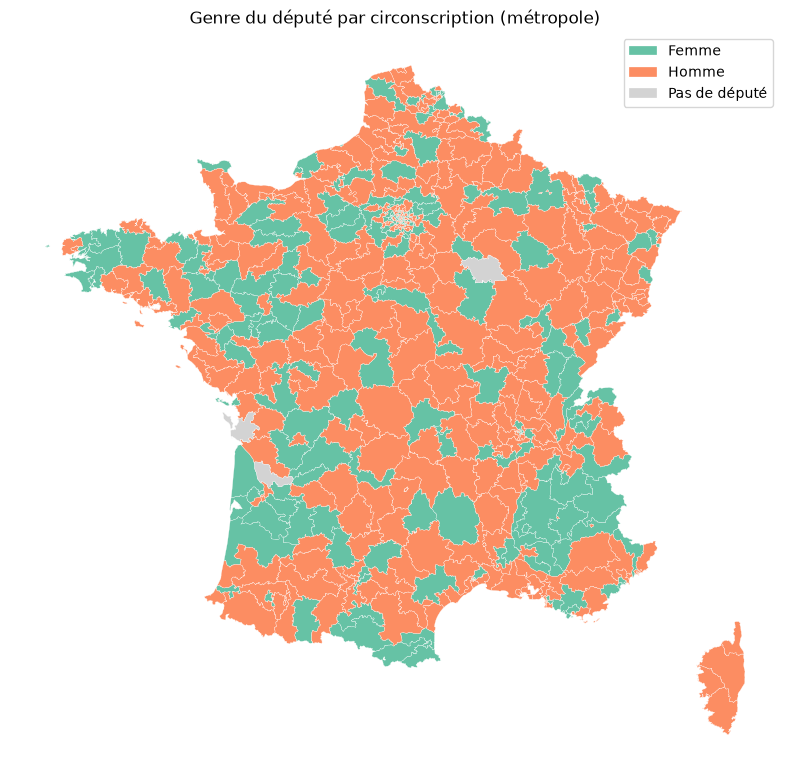

In [12]:
from cartes import carte_genre
carte_genre(carte);

La carte du genre des députés fait apparaître des regroupements régionaux. Les circonscriptions dont l'élu est une femme sont nombreuses en Bretagne, sur la façade atlantique du Sud-Ouest et dans les Alpes, tandis que les députés hommes dominent en Normandie, dans le Nord-Est, dans le Centre et en Corse. Les circonscriptions parisiennes, très petites, ne sont pas lisibles à cette échelle. Les trois circonscriptions en gris n'ont pas de député dans notre base. La répartition géographique ne montre pas de lien visible avec les grandes agglomérations, ce qui s'accorde avec l'écart modeste mesuré plus haut entre les circonscriptions des députées et des députés. Une explication possible, que nous n'avons pas testée, est que les groupes politiques, inégalement implantés selon les régions, présentent inégalement de femmes. Cette lecture visuelle ne remplace pas les tests statistiques précédents.